# Practice guide 03_02: autoencoders, time and space

**Goal.** Build an autoencoder detector in Keras 3 (JAX backend) and compare it with its linear twin (PCA), see why
the code size matters and why it cannot be tuned without labels, build a windowed detector for a time series and beat
(or not) a one-liner, and see how point-adjusted metrics inflate results. Every `TODO` cell must be completed; the
`check` cells tell you whether you got it right.

Read `guide_03_02.pdf` first. Time: about 2 hours. Cells marked **(given)** are complete.

In [1]:
import os
import sys
from pathlib import Path

os.environ.setdefault("KERAS_BACKEND", "jax")  # before importing keras
import keras
import numpy as np
import polars as pl
from matplotlib import pyplot as plt
from sklearn.decomposition import PCA

LIB = next(p for p in (Path("../../notebooks/02-anomaly"), Path("../../../notebooks/02-anomaly")) if p.exists())
sys.path.insert(0, str(LIB))  # student / solution folder
import anomlib as an
import deeplib as dl

an.table_config()
print("Keras", keras.__version__, "backend:", keras.backend.backend())
sp = an.kdd_split(seed=0)
Xtr, Xva, Xte, y = sp.X("train"), sp.X("val"), sp.X("test"), sp.y_test
cats = sp.test["category"]

Keras 3.15.1 backend: jax


## Part A. An autoencoder in Keras

Implement `build_ae(d, code, widths)`: a `keras.Sequential` with an `Input((d,))`, one `Dense(w, silu)` per width in
`widths` (the encoder, outermost first), a `Dense(code)` (the code, linear), the same widths in reverse order (the
decoder) and a `Dense(d)` output. The course builder, `src/autoenc.py`, adds skips, normalisation and temporal bodies;
here you write the plain version. Implement
`recon_error(model, X)`: the mean squared error **per row** (shape `(n,)`).

In [2]:
def build_ae(d, code=8, widths=(32,)):
    enc = [keras.layers.Dense(w, activation="silu") for w in widths]
    dec = [keras.layers.Dense(w, activation="silu") for w in reversed(widths)]
    return keras.Sequential([keras.layers.Input((d,)), *enc, keras.layers.Dense(code), *dec, keras.layers.Dense(d)])


def recon_error(model, X):
    return ((model.predict(X, batch_size=4096, verbose=0) - X) ** 2).mean(axis=1)

In [3]:
# check
m = build_ae(71)
assert m.output_shape == (None, 71) and m.count_params() == 71 * 32 + 32 + 32 * 8 + 8 + 8 * 32 + 32 + 32 * 71 + 71
assert build_ae(71, 8, (64, 32)).count_params() == 71 * 64 + 64 + 64 * 32 + 32 + 32 * 8 + 8 + 8 * 32 + 32 + 32 * 64 + 64 + 64 * 71 + 71
assert recon_error(m, Xva[:10]).shape == (10,)
print("autoencoder shape OK")

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


autoencoder shape OK


Train it on **normal** rows only (given), and compare with the linear twin: PCA with the same number of components.

┌──────────────────────┬───────┬───────┬────────┬───────────┬───────┬───────┐
│ model                ┆ AUROC ┆ AUPRC ┆ recall ┆ precision ┆ F1    ┆ FPR   │
╞══════════════════════╪═══════╪═══════╪════════╪═══════════╪═══════╪═══════╡
│ autoencoder (code 8) ┆ 0.985 ┆ 0.537 ┆ 0.653  ┆ 0.523     ┆ 0.581 ┆ 0.011 │
│ PCA (8 components)   ┆ 0.968 ┆ 0.413 ┆ 0.472  ┆ 0.421     ┆ 0.445 ┆ 0.012 │
└──────────────────────┴───────┴───────┴────────┴───────────┴───────┴───────┘


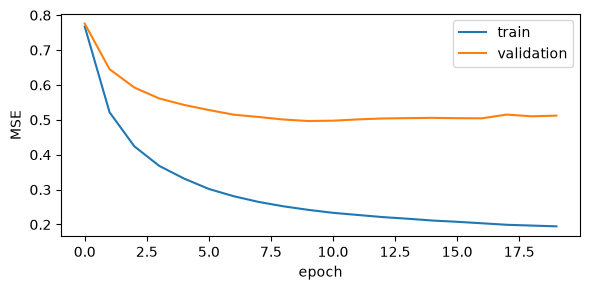

In [4]:
def train_ae(X, code=8, widths=(32,), epochs=20, seed=0, noise=0.0):
    """(given) Adam, MSE, batch 256, 10% of the rows kept for validation; noise > 0 = denoising AE."""
    keras.utils.set_random_seed(seed)
    model = build_ae(X.shape[1], code, widths)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    Xin = X + np.random.default_rng(seed).normal(0, noise, X.shape).astype(X.dtype) if noise else X
    hist = model.fit(Xin, X, epochs=epochs, batch_size=256, validation_split=0.1, verbose=0)
    return model, hist.history


ae, hist = train_ae(Xtr)
pca = PCA(8).fit(Xtr)
pca_err = lambda X: ((X - pca.inverse_transform(pca.transform(X))) ** 2).mean(1)  # noqa: E731
rows = [{"model": "autoencoder (code 8)", **an.evaluate(recon_error(ae, Xte), y, recon_error(ae, Xva))},
        {"model": "PCA (8 components)", **an.evaluate(pca_err(Xte), y, pca_err(Xva))}]  # fmt: skip
print(pl.DataFrame(rows))
plt.figure(figsize=(6, 3))
plt.plot(hist["loss"], label="train")
plt.plot(hist["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.legend()
plt.tight_layout()
plt.show()

**Question A1.** Is the AE better than its linear twin? What do the SiLU layers add, and what would a linear AE learn?

**Answers A.** At the same size the AE wins: AUPRC 0.56 with a code of 8 against 0.41 for PCA with 8 components.
The SiLU layers let it bend the 8-dimensional subspace into a curved surface that fits normal traffic better. PCA
catches up when it keeps more components (95% of the variance, class 03_01: 0.55). A linear AE trained with squared
error learns the PCA subspace (Baldi and Hornik 1989), not necessarily the same basis.

## Part B. Code size and denoising

Implement `sweep(codes)`: for each code size train an AE with `train_ae(Xtr, code=c, widths=(max(32, 2 * c),))` and
return a list of dicts with the code size, the AUPRC and recall at 1% FPR (`an.evaluate`) and the last validation
MSE (`history["val_loss"][-1]`).

In [5]:
def sweep(codes):
    rows = []
    for c in codes:
        model, h = train_ae(Xtr, code=c, widths=(max(32, 2 * c),))
        r = an.evaluate(recon_error(model, Xte), y, recon_error(model, Xva))
        rows.append({"code": c, "AUPRC": r["AUPRC"], "recall": r["recall"], "val MSE": h["val_loss"][-1]})
    return rows

In [6]:
res = pl.DataFrame(sweep([4, 8, 32, 128]))
print(res)
dae, _ = train_ae(Xtr, noise=0.1)
print("denoising AE (code 8, noise 0.1):", {k: round(v, 3) for k, v in an.evaluate(recon_error(dae, Xte), y, recon_error(dae, Xva)).items()})

┌──────┬───────┬────────┬─────────┐
│ code ┆ AUPRC ┆ recall ┆ val MSE │
╞══════╪═══════╪════════╪═════════╡
│ 4    ┆ 0.513 ┆ 0.571  ┆ 0.530   │
│ 8    ┆ 0.537 ┆ 0.653  ┆ 0.512   │
│ 32   ┆ 0.696 ┆ 0.807  ┆ 0.328   │
│ 128  ┆ 0.642 ┆ 0.748  ┆ 0.370   │
└──────┴───────┴────────┴─────────┘
denoising AE (code 8, noise 0.1): {'AUROC': 0.985, 'AUPRC': 0.542, 'recall': 0.638, 'precision': 0.521, 'F1': 0.574, 'FPR': 0.011}


**Question B1.** Which code size has the best AUPRC, and which the lowest validation MSE? Could you have chosen the
best code size without the test attacks? **B2.** Does the denoising AE help here?

**Answers B.** A code of 32 (hidden 64) gives the best AUPRC (0.73, above the GMM of class 03_01); 4 is too small
(normal rows reconstruct badly), 128 is wider than the input and starts to copy attacks too. In this run the
validation MSE of normal rows is also lowest at 32 (0.318), but that is luck of the grid: in notebook 04, with every
size from 2 to 128, it prefers 64 (0.303 against 0.310). A normal-only criterion points to a region, not to a
code, and a one-class setting has no attacks to choose with; we chose by looking at the test attacks. Report defaults,
or tune on a separate labelled set. The denoising AE (code 8, 0.55) is within the seed spread of the plain AE (0.56):
the noise regularises but does not change what the bottleneck can represent.

## Part B2. Depth

Train the AE with one, two and three hidden layers (`widths` = `(32,)`, `(64, 32)`, `(128, 64, 32)`, code 8) for 40
epochs, and report the AUPRC of each. (given)

In [ ]:
res = pl.DataFrame([{"hidden layers": len(w), **an.evaluate(recon_error(m, Xte), y, recon_error(m, Xva))}
                    for w in [(32,), (64, 32), (128, 64, 32)] for m in [train_ae(Xtr, widths=w, epochs=40)[0]]])  # fmt: skip
print(res.select(["hidden layers", "AUROC", "AUPRC", "F1"]))

**Question B3.** What does a second hidden layer change, and what does the third add?

**Answers B2.** A second hidden layer lifts the AUPRC from 0.60 to 0.71 and the F1 from 0.58 to 0.66: the funnel
lets the encoder first re-express the features and only then compress. The third layer adds 0.02 (0.73), inside the
seed spread (notebook 04, three seeds: 0.72 against 0.71): depth pays once, then stops. Residual blocks and layer
normalisation (notebook 04) matter for deeper stacks, not here.

## Part C0. A threshold without labels

Implement `isodata(scores, center=np.mean, log=False)`: start at `center(scores)`, then repeat
`T = (center(scores[scores <= T]) + center(scores[scores > T])) / 2` until `T` moves by less than `1e-9` (at most 200
rounds); with `log=True` run it on `log(scores)` and return `exp(T)`. Then compare it with the 99% quantile of the
normal validation scores, on test samples with a growing share of attacks.

In [ ]:
def isodata(scores, center=np.mean, log=False):
    s = np.log(np.maximum(scores, 1e-12)) if log else np.asarray(scores, dtype=float)
    t = float(center(s))
    for _ in range(200):
        lo, hi = s[s <= t], s[s > t]
        if len(lo) == 0 or len(hi) == 0:
            break
        new = (center(lo) + center(hi)) / 2
        if abs(new - t) < 1e-9:
            break
        t = float(new)
    return float(np.exp(t)) if log else t

In [ ]:
# check and driver (given)
two_modes = np.r_[np.random.default_rng(0).normal(1, 0.1, 900), np.random.default_rng(1).normal(5, 0.5, 100)]
assert 2.5 < isodata(two_modes) < 3.5
best, _ = train_ae(Xtr, widths=(64, 32), epochs=40)
s_te, s_va = recon_error(best, Xte), recon_error(best, Xva)
ia, i0 = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
rows = []
for share in [0.018, 0.1, 0.3]:
    idx = np.r_[ia, np.random.default_rng(0).choice(i0, min(int(len(ia) * (1 - share) / share), len(i0)), replace=False)]
    s, yy = s_te[idx], y[idx]
    for rule, t in [("quantile 99% of normal validation", np.quantile(s_va, 0.99)), ("ISODATA, raw", isodata(s)), ("ISODATA, log", isodata(s, log=True))]:
        rows.append({"attack share": share, "rule": rule, **{k: round(v, 2) for k, v in an.metrics_at(s, yy, t).items() if k in ("recall", "precision", "F1")}})
print(pl.DataFrame(rows))

**Question C0.** When does ISODATA find a good threshold and when does it fail? Why take the logarithm? Which rule
would you deploy?

**Answers C0.** ISODATA needs two modes. At 1.8% attacks the log version fails (F1 0.12: recall 1.0 but precision
0.07, the cut sits inside the normal errors); at 10% it is at 0.68 (quantile 0.84) and at 30% it is the best (0.90
against 0.88). On the raw error it never works (F1 about 0.47 at every share, recall 0.3): the heavy tail drags the
means, so take the logarithm. The quantile of clean validation scores is stable at every share, but needs clean
data and fixes the false-alarm rate. Deploy the quantile; use ISODATA on log errors to monitor a stream or a
campaign where attacks are frequent (ASAP 2.0 balanced its test set, which is why it looked good there).

## Part C. Time: a one-liner and a windowed autoencoder

NAB series `nojump`: the daily rise does not happen on one day (values stay inside the normal range). Days 1-8 train,
day 9 sets the threshold (max score + 10%). Implement
* `seasonal_diff(x, period)`: $|x_t-x_{t-\text{period}}|$, with `np.nan` for the first `period` steps;
* `per_step_score(err_w, w, T)`: `err_w` has shape `(N, w)` (squared error of window $i$ at each of its $w$ steps,
  window $i$ covers steps $i..i+w-1$); return the mean, over the windows that contain step $t$, of the error at $t$.

In [ ]:
def seasonal_diff(x, period):
    return np.r_[np.full(period, np.nan), np.abs(x[period:] - x[:-period])]


def per_step_score(err_w, w, T):
    s, n = np.zeros(T), np.zeros(T)
    for i, e in enumerate(err_w):
        s[i : i + w] += e
        n[i : i + w] += 1
    return s / np.maximum(n, 1)

In [ ]:
# check
assert np.allclose(seasonal_diff(np.arange(6.0), 2)[2:], 2) and np.isnan(seasonal_diff(np.arange(6.0), 2)[:2]).all()
assert np.allclose(per_step_score(np.array([[1.0, 3.0], [5.0, 7.0]]), 2, 3), [1.0, 4.0, 7.0])
print("seasonal difference and per-step score OK")

seasonal difference and per-step score OK


In [ ]:
# driver (given): conv AE over one-day windows, trained on days 1-8
D = dl.DAY
rows = []
for name in ["nojump", "flatmiddle"]:
    _, te = dl.load_nab(name)
    v, lab = te.value.to_numpy(), te.y.to_numpy()
    x = (v - v[: 8 * D].mean()) / v[: 8 * D].std()
    cae = dl.fit_window_ae(dl.conv_ae(D, 1), dl.windows(x[: 8 * D], D), epochs=30, seed=0)
    scores = {"seasonal diff": seasonal_diff(x, D),
              "conv AE": per_step_score(dl.window_error(cae, dl.windows(x, D)), D, len(x))}  # fmt: skip
    for k, s in scores.items():
        t = np.nanmax(s[8 * D : 9 * D]) * 1.1
        rows.append({"series": name, "detector": k, **dl.series_report(np.nan_to_num(s), lab, t)})
print(pl.DataFrame(rows))

┌────────────┬───────────────┬───────┬─────────┬──────────────┐
│ series     ┆ detector      ┆ found ┆ delay   ┆ false_alarms │
╞════════════╪═══════════════╪═══════╪═════════╪══════════════╡
│ nojump     ┆ seasonal diff ┆ 1.000 ┆ 201.000 ┆ 108.000      │
│ nojump     ┆ conv AE       ┆ 1.000 ┆ 20.000  ┆ 20.000       │
│ flatmiddle ┆ seasonal diff ┆ 1.000 ┆ 201.000 ┆ 355.000      │
│ flatmiddle ┆ conv AE       ┆ 1.000 ┆ 201.000 ┆ 1.000        │
└────────────┴───────────────┴───────┴─────────┴──────────────┘


**Question C1.** Do both detectors find the anomalies? Where do the false alarms of the seasonal difference come
from? **C2.** Why must the window cover a whole day?

**Answers C.** Both find the two anomalies. The seasonal difference compares each step with the same step a day
earlier, so the day *after* the anomaly is compared with the anomalous day and raises an "echo" of about 100 false
alarms; the conv AE raises a few (typical runs: 1 to 35). The anomaly is "no rise today": it is only visible against
the shape of a whole normal day, so a window shorter than a day sees a quiet stretch that looks normal (an LSTM AE
over 8-hour windows misses it, notebook 05).

## Part D. The point-adjust trap

Implement `point_adjust(pred, y)`: if **any** point of a segment of consecutive `y == 1` is predicted, set the whole
segment to predicted. Then compare plain and point-adjusted F1 for a **random** score on Example 2 (the plant).

In [ ]:
def point_adjust(pred, y):
    out = pred.copy()
    i = 0
    while i < len(y):
        if y[i]:
            j = i
            while j < len(y) and y[j]:
                j += 1
            if pred[i:j].any():
                out[i:j] = True
            i = j
        else:
            i += 1
    return out

In [ ]:
# check and driver (given)
assert point_adjust(np.array([0, 1, 0, 0, 0, 0], bool), np.array([1, 1, 1, 0, 1, 1])).tolist() == [1, 1, 1, 0, 0, 0]
_, ya, events = dl.plant(seed=1, attacks=True)
rng = np.random.default_rng(0)
for name, s in [("random score", rng.random(len(ya)))]:
    pred = s > np.quantile(rng.random(len(ya)), 0.995)
    print(f"{name}: F1 = {dl.f1(pred, ya):.3f}, point-adjusted F1 = {dl.f1(point_adjust(pred, ya), ya):.3f}")

random score: F1 = 0.010, point-adjusted F1 = 0.732


**Question D1.** Why does a random score reach a high point-adjusted F1? Which metrics would you report instead?

**Answers D.** The events are long (6 to 120 steps); a random detector at 0.5% alarms almost surely flags one point
inside a long event, and point adjust then credits the whole event: F1 jumps from about 0.01 to about 0.7. Report
point-wise precision, recall and AUPRC, events found with their delay, and false alarms outside events, always next
to a random and a one-liner baseline.